# Wheat_analysis — du cours du blé à une allocation de portefeuille

**Objectif** : modéliser le cours du blé à partir de variables climatiques, de sentiment de marché, du dollar et du pétrole, puis utiliser ce modèle pour gérer une position sur le blé.

1. **Chargement des données** (blé, sentiment WASDE, RONI, dollar, WTI)
2. **Qualité des données** (fréquence, couverture, trous, doublons)
3. **Formatage des données** (fréquence mensuelle, raccord du dollar, centrage-réduction, valeurs extrêmes)
4. **Étude des données** (corrélations en niveaux et en variations, décalages temporels, stabilité)
5. **Modèle** (régression des variations du blé avec 3 variables climatiques, évaluée hors échantillon)
6. **Portefeuille** (simulation mois par mois sous contrainte de risque)

| Variable | Source | Fréquence native |
|---|---|---|
| `wheat_price_usd` — prix du blé (USD/t) | FMI, série PWHEAMT | mensuelle |
| `wasde_sentiment` — score NLP du marché | rapports WASDE de l'USDA (PDF locaux), lexique Loughran-McDonald adapté au blé | ~1 rapport/mois, dates irrégulières |
| `roni_index` — favorabilité météo macro (El Niño / La Niña) | NOAA CPC, indice RONI | mensuelle (moyenne glissante sur 3 mois) |
| `dxy_index` — dollar | FRED : DTWEXM (jusqu'en 2019) raccordé à DTWEXBGS | quotidienne |
| `wti_price_usd` — pétrole | FRED : DCOILWTICO | quotidienne |

> **Sources et clé FRED.** Les téléchargements sont mis en cache dans `data/cache/` (mettre `REFRESH = True` pour les refaire). Le téléchargement FRED nécessite la variable d'environnement `FRED_API_KEY` ; elle n'est pas écrite dans le notebook. Le sentiment WASDE est recalculé ici à partir des fichiers de `data/wasde_txt_reports/` avec les mêmes règles de scoring que le notebook `Wheat_Data.ipynb`, mais avec une **datation corrigée** (voir §1.3).

In [1]:
import logging
import os
import re
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from pypdf import PdfReader

logging.getLogger("pypdf").setLevel(logging.ERROR)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

DATA_DIR = Path("./data")
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
WASDE_DIR = DATA_DIR / "wasde_txt_reports"
START, END = "1992-01-01", "2026-12-31"
REFRESH = False  # True : retélécharge les sources au lieu de lire data/cache/

# --- Style graphique : une couleur par variable, toujours la même ---
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS = {
    "wheat_price_usd": "#2a78d6",   # bleu
    "wasde_sentiment": "#eb6834",   # orange
    "roni_index": "#1baf7a",        # aqua
    "dxy_index": "#eda100",         # jaune
    "wti_price_usd": "#e87ba4",     # magenta
}
LABELS = {
    "wheat_price_usd": "Prix du blé (USD/t)",
    "wasde_sentiment": "Sentiment WASDE (score net, -1 à +1)",
    "roni_index": "RONI (°C)",
    "dxy_index": "Dollar (indice large)",
    "wti_price_usd": "Pétrole WTI (USD/baril)",
}
SHORT = {"wheat_price_usd": "Blé", "wasde_sentiment": "Sentiment", "roni_index": "RONI",
         "dxy_index": "Dollar", "wti_price_usd": "WTI"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titlelocation": "left", "font.size": 10, "lines.linewidth": 1.6,
    "legend.frameon": False, "figure.dpi": 100,
})

## 1. Chargement des données

### 1.1 Blé (FMI), RONI (NOAA), dollar et pétrole (FRED)

In [2]:
def cached(name, builder):
    path = CACHE_DIR / name
    if path.exists() and not REFRESH:
        return pd.read_csv(path, parse_dates=["date"])
    frame = builder()
    frame.to_csv(path, index=False)
    return frame


# ---------- Blé : FMI (SDMX) ----------
IMF_URL = (
    "https://api.imf.org/external/sdmx/3.0/data/dataflow/IMF.RES/PCPS/9.0.0/"
    f"*.PWHEAMT.USD.M?c%5BTIME_PERIOD%5D=ge:1956-12-31+le:{END}"
    "&attributes=all&detail=full&includeHistory=true&limit=100"
)

def fetch_imf_wheat():
    r = requests.get(IMF_URL, headers={"Accept": "application/vnd.sdmx.data+json;version=2.0.0"}, timeout=60)
    r.raise_for_status()
    data = r.json()["data"]
    periods = data["structures"][0]["dimensions"]["observation"][0]["values"]
    series = list(data["dataSets"][0]["series"].values())
    if len(series) != 1:
        raise ValueError(f"Une seule série attendue, {len(series)} reçues")
    rows = [
        {"date": pd.to_datetime(periods[int(i)]["value"].replace("-M", "-"), format="%Y-%m"),
         "wheat_price_usd": pd.to_numeric(obs[0], errors="coerce")}
        for i, obs in series[0]["observations"].items()
    ]
    out = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
    return out[out["date"] >= START]


# ---------- RONI : NOAA CPC ----------
RONI_URL = "https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/"
SEASON_END_MONTH = {"DJF": 2, "JFM": 3, "FMA": 4, "MAM": 5, "AMJ": 6, "MJJ": 7,
                    "JJA": 8, "JAS": 9, "ASO": 10, "SON": 11, "OND": 12, "NDJ": 1}

def fetch_roni():
    page = requests.get(RONI_URL, timeout=60)
    page.raise_for_status()
    # La table utile est la seule dont les colonnes sont les saisons DJF ... NDJ
    table = next(t for t in pd.read_html(StringIO(page.text))
                 if {"DJF", "NDJ"} <= {str(c).split()[0] for c in t.columns})
    table = table.rename(columns={table.columns[0]: "year"})
    long = table.melt(id_vars="year", var_name="season_label", value_name="roni_index")
    long["year"] = pd.to_numeric(long["year"], errors="coerce")
    long["roni_index"] = pd.to_numeric(long["roni_index"], errors="coerce")
    long = long.dropna(subset=["year"])
    # Une valeur trimestrielle est rattachée à son dernier mois (NDJ de l'année Y -> janvier Y+1)
    long["month"] = long["season_label"].str.split().str[0].map(SEASON_END_MONTH)
    long["date"] = pd.to_datetime({"year": long["year"].astype(int) + long["month"].eq(1),
                                   "month": long["month"], "day": 1})
    return long.loc[long["date"] >= START, ["date", "roni_index"]].sort_values("date").reset_index(drop=True)


# ---------- Dollar et pétrole : FRED ----------
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"

def fetch_fred(series_id, column):
    key = os.environ.get("FRED_API_KEY")
    if not key:
        raise RuntimeError("Définir la variable d'environnement FRED_API_KEY "
                           "(ou fournir le cache data/cache/).")
    r = requests.get(FRED_URL, params={"series_id": series_id, "api_key": key,
                                       "file_type": "json", "observation_start": START}, timeout=60)
    r.raise_for_status()
    obs = pd.DataFrame(r.json()["observations"])[["date", "value"]].rename(columns={"value": column})
    obs["date"] = pd.to_datetime(obs["date"])
    obs[column] = pd.to_numeric(obs[column], errors="coerce")  # FRED code les jours sans cotation par "."
    return obs


wheat_raw = cached("imf_wheat.csv", fetch_imf_wheat)
roni_raw = cached("noaa_roni.csv", fetch_roni)
dxy_history_raw = cached("fred_dtwexm.csv", lambda: fetch_fred("DTWEXM", "dxy_history"))
dxy_current_raw = cached("fred_dtwexbgs.csv", lambda: fetch_fred("DTWEXBGS", "dxy_current"))
wti_raw = cached("fred_wti.csv", lambda: fetch_fred("DCOILWTICO", "wti_price_usd"))

for name, frame in {"blé": wheat_raw, "RONI": roni_raw, "dollar (historique)": dxy_history_raw,
                    "dollar (courant)": dxy_current_raw, "WTI": wti_raw}.items():
    print(f"{name:22s} {len(frame):5d} lignes  {frame['date'].min():%Y-%m-%d} -> {frame['date'].max():%Y-%m-%d}")

blé                      418 lignes  1992-01-01 -> 2026-10-01
RONI                     421 lignes  1992-01-01 -> 2027-01-01
dollar (historique)     7305 lignes  1992-01-01 -> 2019-12-31
dollar (courant)        5440 lignes  2006-01-02 -> 2026-11-06
WTI                     9090 lignes  1992-01-01 -> 2026-11-03


### 1.2 Sentiment WASDE (NLP)

Les rapports mensuels WASDE de l'USDA ont été téléchargés en PDF puis réduits aux paragraphes mentionnant le blé (`*_wheat.txt`). Le score est le *net sentiment* lexical : (mots haussiers − mots baissiers) / (mots haussiers + mots baissiers), de −1 (baissier pour le prix) à +1 (haussier). Les listes de mots et l'extraction du bloc « WHEAT: » reprennent celles de `Wheat_Data.ipynb`.

### 1.3 Pourquoi on redate les rapports
Les noms de fichiers USDA mélangent trois formats : `MM-DD-YYYY` (jusqu'à 2018), `DD-MM-YYYY` (fin 2018 à 2021) et `MMYY`. Les lire tous en `DD-MM-YYYY` inverse le jour et le mois de la plupart des rapports et en perd une quarantaine. On utilise donc la **date d'approbation imprimée dans l'en-tête du PDF**, et le nom de fichier (`MM-DD-YYYY`) uniquement en repli.

In [3]:
BULLISH_WORDS = {"drought", "dry", "deficit", "freeze", "frost", "damage", "reduced", "decline", "declining",
                 "lower", "cut", "tight", "tightened", "shrinking", "drop", "dropped", "stress", "shortage",
                 "delayed", "deteriorated", "poor"}
BEARISH_WORDS = {"record", "favorable", "bumper", "exceed", "exceeded", "abundant", "expanded", "expansion",
                 "increase", "increased", "increasing", "higher", "rebound", "rebounded", "surge", "surplus",
                 "large", "larger", "adequate", "improved", "improving", "heavy"}
MONTH_NAMES = "January|February|March|April|May|June|July|August|September|October|November|December"
# Erratas partiels (souvent sur d'autres cultures) : ce ne sont pas des rapports mensuels complets
PARTIAL_ERRATA = re.compile(r"revision|announcement|ending_stocks", re.IGNORECASE)


def extract_wheat_narrative(text):
    # Bloc narratif "WHEAT:" sans les lignes de tableaux numériques
    text = re.sub(r"\r\n|\r", "\n", text)
    start = re.search(r"\s*WHEAT:\s*", text, re.IGNORECASE) or re.search(r"\n\s*WHEAT\b[^\n]*\n", text, re.IGNORECASE)
    if not start:
        return ""
    rest = text[start.end():]
    end = re.search(r"\n\s*(?:COARSE GRAINS|CORN|FEED GRAINS|OILSEEDS|SOYBEANS|RICE|COTTON|WASDE-\d+|TABLE \d+):",
                    rest, re.IGNORECASE)
    section = rest[:end.start()] if end else rest[:5000]
    lines = [ln.strip() for ln in section.split("\n")]
    return " ".join(ln for ln in lines if ln and len(re.findall(r"\b\d+(?:\.\d+)?\b", ln)) < 4)


def date_from_pdf_header(pdf_path):
    if not pdf_path.exists():
        return pd.NaT
    try:
        reader = PdfReader(pdf_path)
        text = " ".join(reader.pages[i].extract_text() or "" for i in range(min(2, len(reader.pages))))
    except Exception:
        return pd.NaT
    m = (re.search(rf"(?:Approved by the World Agricultural Outlook Board|WASDE\s*-\s*\d+)[^A-Za-z]*?"
                   rf"({MONTH_NAMES})\s+([0-3]?\d),?\s+((?:19|20)\d\d)", text, re.IGNORECASE)
         or re.search(rf"({MONTH_NAMES})\s+([0-3]?\d),?\s+((?:19|20)\d\d)", text, re.IGNORECASE))
    return pd.to_datetime(f"{m[1]} {m[2]} {m[3]}", errors="coerce") if m else pd.NaT


def date_from_filename(name):
    # Repli : les PDF sans date lisible (scans, 1992-1994 ; quelques fichiers 1998 et 2016-2017) sont en MM-DD-YYYY
    m = re.search(r"(?<!\d)(0[1-9]|1[0-2])-([0-3]\d)-((?:19|20)\d\d)(?!\d)", name)
    if m:
        return pd.to_datetime(f"{m[3]}-{m[1]}-{m[2]}", errors="coerce")
    m = re.search(r"(?<!\d)(0[1-9]|1[0-2])(\d{2})(?!\d)", name)  # MMYY
    if m:
        year = int(m[2])
        return pd.Timestamp(year + (2000 if year <= 69 else 1900), int(m[1]), 1)
    return pd.NaT


def build_wasde_reports():
    rows = []
    for txt in sorted(WASDE_DIR.glob("*_wheat.txt")):
        pdf = txt.with_name(txt.name.replace("_wheat.txt", ".pdf"))
        date, source = date_from_pdf_header(pdf), "en-tête PDF"
        if pd.isna(date):
            date, source = date_from_filename(txt.name), "nom de fichier"
        narrative = extract_wheat_narrative(txt.read_text(encoding="utf-8", errors="replace"))
        tokens = re.findall(r"\b[a-z]+\b", narrative.lower())
        bull = sum(t in BULLISH_WORDS for t in tokens)
        bear = sum(t in BEARISH_WORDS for t in tokens)
        rows.append({
            "date": date, "file": txt.name, "date_source": source,
            "partial_errata": bool(PARTIAL_ERRATA.search(txt.name)),
            "narrative_words": len(tokens), "bull_words": bull, "bear_words": bear,
            # Narratif vide (PDF scannés) => pas d'information (NaN), et non un score neutre
            "wasde_sentiment": (bull - bear) / max(1, bull + bear) if tokens else np.nan,
        })
    return pd.DataFrame(rows)


wasde_reports = cached("wasde_reports.csv", build_wasde_reports)
print(f"{len(wasde_reports)} fichiers WASDE lus ; {wasde_reports['date'].isna().sum()} sans date exploitable")
wasde_reports.head()

382 fichiers WASDE lus ; 0 sans date exploitable


,date,file,date_source,partial_errata,narrative_words,bull_words,bear_words,wasde_sentiment
0,2013-08-12,ORIGwasde-08-12-2013_wheat.txt,en-tête PDF,False,595,7,13,-0.300000
1,2013-07-11,R1wasde-07-11-2013_wheat.txt,en-tête PDF,False,569,6,15,-0.428571
2,2003-01-10,wasde-01-10-2003_wheat.txt,en-tête PDF,False,225,5,5,0.000000
3,2014-01-10,wasde-01-10-2014_wheat.txt,en-tête PDF,False,503,6,6,0.000000
4,2001-01-11,wasde-01-11-2001_wheat.txt,en-tête PDF,False,102,1,1,0.000000


## 2. Qualité des données

Pour chaque série : période couverte, fréquence réelle (écart médian entre observations), valeurs manquantes, doublons de date, mois sans observation, valeurs non positives, et ordres de grandeur.

In [4]:
RAW = {
    "wheat_price_usd": wheat_raw,
    "wasde_sentiment": wasde_reports.loc[~wasde_reports["partial_errata"] & wasde_reports["date"].notna(),
                                         ["date", "wasde_sentiment"]],
    "roni_index": roni_raw,
    "dxy_history": dxy_history_raw,
    "dxy_current": dxy_current_raw,
    "wti_price_usd": wti_raw,
}


def quality_summary(frame, col):
    s = frame.set_index("date")[col].sort_index()
    valid = s.dropna()
    median_gap = valid.index.to_series().diff().dt.days.median()
    months = valid.index.to_period("M")
    per_month = valid.groupby(months).size()
    full = pd.period_range(months.min(), months.max(), freq="M")
    return {
        "début": valid.index.min().date(), "fin": valid.index.max().date(),
        "n_obs": len(valid), "n_manquants": int(s.isna().sum()),
        "dates_dupliquées": int(s.index.duplicated().sum()),
        "fréquence": ("quotidienne" if median_gap <= 4 else "mensuelle" if 25 <= median_gap <= 35 else "irrégulière"),
        "max_obs/mois": int(per_month.max()),
        "mois_sans_obs": len(full.difference(per_month.index)),
        "valeurs_≤0": int((valid <= 0).sum()) if col not in ("wasde_sentiment", "roni_index") else "n.a.",
        "min": valid.min(), "médiane": valid.median(), "max": valid.max(),
    }


quality = pd.DataFrame({name: quality_summary(frame, name) for name, frame in RAW.items()}).T
quality[["min", "médiane", "max"]] = quality[["min", "médiane", "max"]].astype(float).round(2)
display(quality)

,début,fin,n_obs,n_manquants,dates_dupliquées,fréquence,max_obs/mois,mois_sans_obs,valeurs_≤0,min,médiane,max
wheat_price_usd,1992-01-01,2026-10-01,418,0,0,mensuelle,1,0,0,88.55,170.72,444.16
wasde_sentiment,1998-02-11,2026-10-09,336,37,1,mensuelle,2,10,n.a.,-1.00,-0.25,0.82
roni_index,1992-01-01,2026-10-01,418,3,0,mensuelle,1,0,n.a.,-1.70,-0.20,2.30
dxy_history,1992-01-02,2019-12-31,7094,211,0,quotidienne,23,0,0,68.01,87.55,113.10
dxy_current,2006-01-02,2026-11-06,5227,213,0,quotidienne,23,0,0,85.47,110.30,130.04
wti_price_usd,1992-01-02,2026-11-03,8068,1022,0,quotidienne,23,0,1,-36.98,56.46,145.31


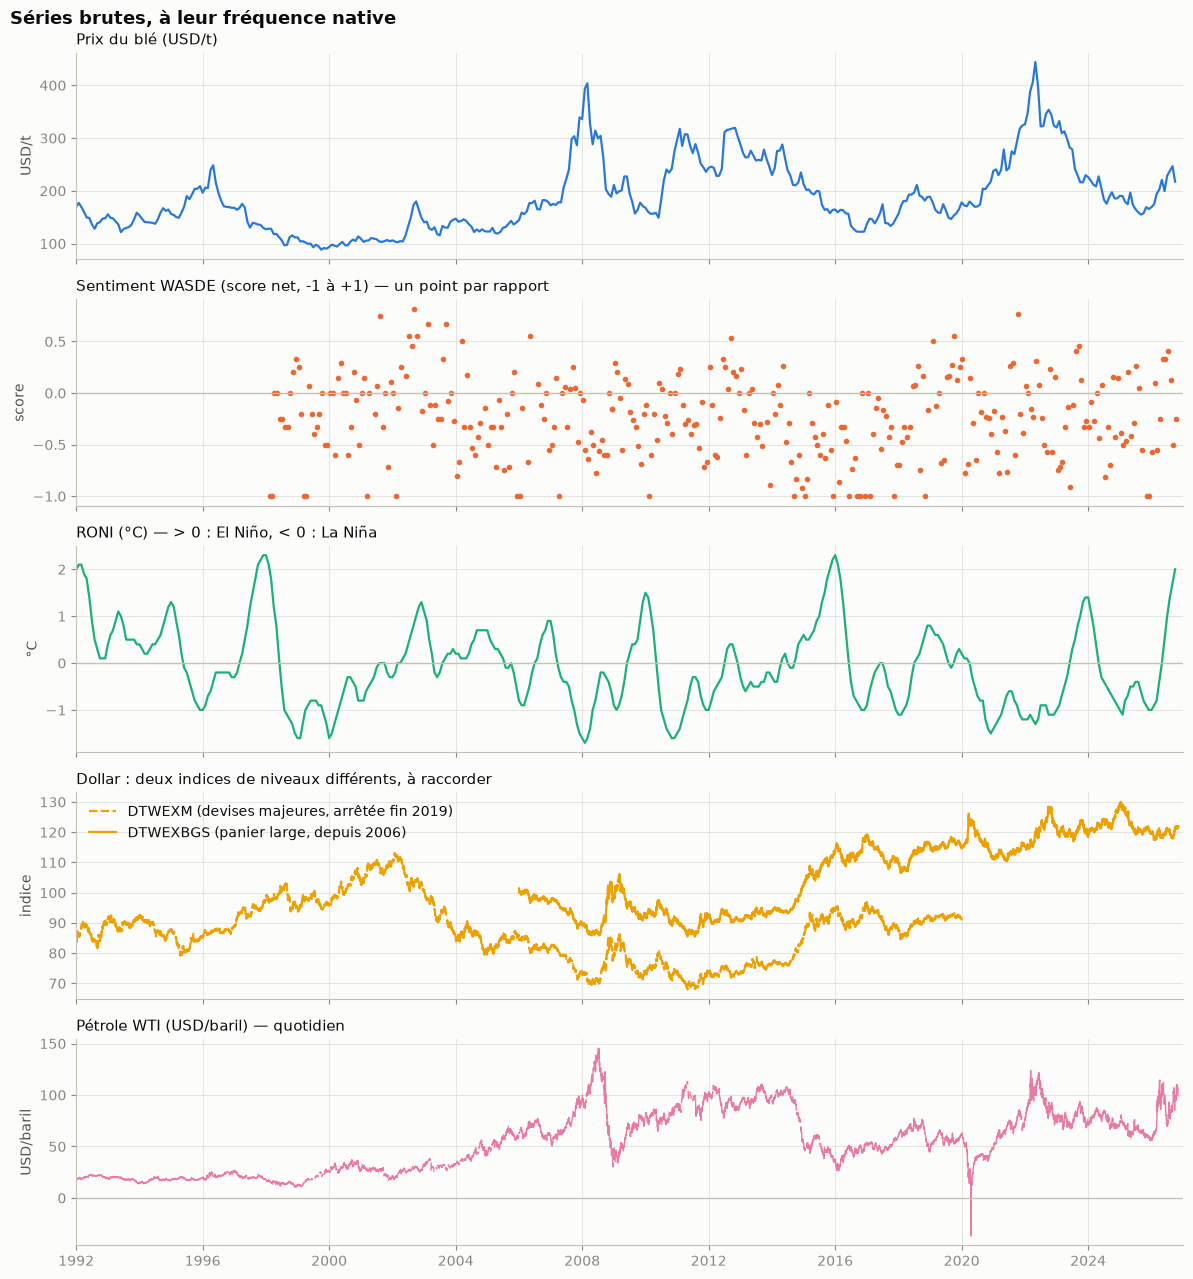

In [5]:
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True)
xlim = (pd.Timestamp(START), pd.Timestamp("2026-12-31"))

ax = axes[0]
ax.plot(wheat_raw["date"], wheat_raw["wheat_price_usd"], color=COLORS["wheat_price_usd"])
ax.set_title(LABELS["wheat_price_usd"]); ax.set_ylabel("USD/t")

ax = axes[1]
w = RAW["wasde_sentiment"].dropna()
ax.plot(w["date"], w["wasde_sentiment"], "o", ms=3, color=COLORS["wasde_sentiment"])
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_title(LABELS["wasde_sentiment"] + " — un point par rapport"); ax.set_ylabel("score")

ax = axes[2]
ax.plot(roni_raw["date"], roni_raw["roni_index"], color=COLORS["roni_index"])
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_title(LABELS["roni_index"] + " — > 0 : El Niño, < 0 : La Niña"); ax.set_ylabel("°C")

ax = axes[3]
ax.plot(dxy_history_raw["date"], dxy_history_raw["dxy_history"], color=COLORS["dxy_index"], ls="--", label="DTWEXM (devises majeures, arrêtée fin 2019)")
ax.plot(dxy_current_raw["date"], dxy_current_raw["dxy_current"], color=COLORS["dxy_index"], label="DTWEXBGS (panier large, depuis 2006)")
ax.set_title("Dollar : deux indices de niveaux différents, à raccorder"); ax.set_ylabel("indice")
ax.legend(loc="upper left")

ax = axes[4]
ax.plot(wti_raw["date"], wti_raw["wti_price_usd"], color=COLORS["wti_price_usd"], lw=1)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_title(LABELS["wti_price_usd"] + " — quotidien"); ax.set_ylabel("USD/baril")

axes[-1].set_xlim(xlim)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(4))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Séries brutes, à leur fréquence native", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [6]:
# ---- Contrôles spécifiques par source ----
print("=== WTI : valeurs <= 0 ===")
print(wti_raw.loc[wti_raw["wti_price_usd"] <= 0].to_string(index=False))

print("\n=== FRED : jours sans cotation ('.' dans l'API), ignorés ===")
for name, frame, col in [("dollar historique", dxy_history_raw, "dxy_history"),
                         ("dollar courant", dxy_current_raw, "dxy_current"), ("WTI", wti_raw, "wti_price_usd")]:
    print(f"{name:18s} {int(frame[col].isna().sum()):4d} jours manquants sur {len(frame)}")

print("\n=== RONI : saisons pas encore publiées ===")
print(roni_raw.loc[roni_raw["roni_index"].isna(), "date"].dt.strftime("%Y-%m").tolist())

reports = wasde_reports[~wasde_reports["partial_errata"]]
print("\n=== WASDE ===")
print(f"Fichiers : {len(wasde_reports)} dont {int(wasde_reports['partial_errata'].sum())} erratas partiels exclus")
print("Source de la date :", reports["date_source"].value_counts().to_dict())
print(f"Rapports sans narratif blé (PDF scannés / bloc 'WHEAT:' absent) : {int(reports['wasde_sentiment'].isna().sum())}")
print("  par année :", reports.loc[reports["wasde_sentiment"].isna(), "date"].dt.year.value_counts().sort_index().to_dict())
scored = reports.dropna(subset=["wasde_sentiment"])
print(f"Rapports sans aucun mot du lexique (score = 0 par construction) : {int((scored['bull_words'] + scored['bear_words'] == 0).sum())} sur {len(scored)}")
print("Jour du mois des rapports datés par l'en-tête PDF (doit se concentrer autour du 8-12) :")
print(reports.loc[reports["date_source"] == "en-tête PDF", "date"].dt.day.value_counts().sort_index().to_dict())

=== WTI : valeurs <= 0 ===
      date  wti_price_usd
2020-04-20         -36.98

=== FRED : jours sans cotation ('.' dans l'API), ignorés ===
dollar historique   211 jours manquants sur 7305
dollar courant      213 jours manquants sur 5440
WTI                1022 jours manquants sur 9090

=== RONI : saisons pas encore publiées ===
['2026-11', '2026-12', '2027-01']

=== WASDE ===
Fichiers : 382 dont 9 erratas partiels exclus
Source de la date : {'en-tête PDF': 329, 'nom de fichier': 44}
Rapports sans narratif blé (PDF scannés / bloc 'WHEAT:' absent) : 37
  par année : {1992: 12, 1993: 12, 1994: 12, 2008: 1}
Rapports sans aucun mot du lexique (score = 0 par construction) : 7 sur 336
Jour du mois des rapports datés par l'en-tête PDF (doit se concentrer autour du 8-12) :
{8: 26, 9: 54, 10: 80, 11: 61, 12: 105, 14: 2, 28: 1}


## 3. Formatage des données : fréquence mensuelle, raccord du dollar, centrage

Règles appliquées :
- **moyenne mensuelle** de toutes les observations d'un mois (une seule observation : inchangée) ;
- pour les séries quotidiennes, le **dernier mois est écarté s'il est en cours** (peu de jours cotés) ; les trous internes de la source sont conservés (moyenne des jours disponibles) mais signalés ;
- le dollar est reconstitué en **chaînant** DTWEXM sur DTWEXBGS au premier mois commun (janvier 2006) : leur rapport n'étant pas constant, une échelle unique créerait un saut artificiel ;
- échantillon commun = mois où les 5 variables sont observées ; puis **centrage-réduction** (moyenne 0, écart-type 1) sur cet échantillon.

In [7]:
DAILY = ["dxy_history", "dxy_current", "wti_price_usd"]
monthly, counts = {}, {}
for name, frame in RAW.items():
    s = frame.set_index("date")[name].dropna().sort_index()
    grouped = s.groupby(s.index.to_period("M").to_timestamp())
    monthly[name], counts[name] = grouped.mean(), grouped.size()
    if name in DAILY:
        # Seul le dernier mois est écarté s'il est en cours (peu de jours cotés)
        last = counts[name].index[-1]
        if counts[name].iloc[-1] < 0.7 * counts[name].median():
            print(f"{name}: mois en cours {last:%Y-%m} ({counts[name].iloc[-1]} jours) mis à NaN")
            monthly[name] = monthly[name].mask(monthly[name].index == last)
        # Les trous internes de la source sont conservés (moyenne des jours disponibles) mais signalés
        sparse = counts[name][(counts[name] < 15) & (counts[name].index < last)]
        print(f"{name}: {len(sparse)} mois avec moins de 15 jours cotés (moyenne conservée)"
              + (f", entre {sparse.index.min():%Y-%m} et {sparse.index.max():%Y-%m}" if len(sparse) else ""))

# ---- Raccord du dollar ----
# Les deux indices ont des niveaux différents et leur rapport n'est pas constant : une échelle unique
# créerait un saut artificiel à la jonction. On "chaîne" donc l'historique sur l'indice courant au
# premier mois commun, de sorte que la variation mensuelle à la jonction est celle de l'historique.
overlap = pd.concat([monthly["dxy_history"], monthly["dxy_current"]], axis=1).dropna()
junction = overlap.index[0]
scale = overlap.loc[junction, "dxy_current"] / overlap.loc[junction, "dxy_history"]
ratio = overlap["dxy_current"] / overlap["dxy_history"]
print(f"\nRaccord dollar : {len(overlap)} mois de recouvrement ({overlap.index.min():%Y-%m} -> {overlap.index.max():%Y-%m})")
print(f"  rapport courant/historique : {scale:.3f} à la jonction ; sur le recouvrement : médiane {ratio.median():.3f}, "
      f"5e-95e pct [{ratio.quantile(.05):.3f}, {ratio.quantile(.95):.3f}] (non constant)")
print(f"  corrélation des niveaux : {overlap['dxy_current'].corr(overlap['dxy_history']):.3f} ; "
      f"corrélation des variations mensuelles (log) : {np.log(overlap).diff().corr().iloc[0, 1]:.3f}")
dxy_index = monthly["dxy_current"].combine_first(monthly["dxy_history"] * scale)

monthly_all = pd.concat({
    "wheat_price_usd": monthly["wheat_price_usd"],
    "wasde_sentiment": monthly["wasde_sentiment"],
    "roni_index": monthly["roni_index"],
    "dxy_index": dxy_index,
    "wti_price_usd": monthly["wti_price_usd"],
}, axis=1)
monthly_all = monthly_all.reindex(pd.date_range(monthly_all.index.min(), monthly_all.index.max(), freq="MS"))
monthly_all.index.name = "date"
monthly_all.to_csv(CACHE_DIR / "monthly_panel.csv")  # réutilisé par Wheat_portfolio.ipynb

coverage = pd.DataFrame({
    "premier_mois": monthly_all.apply(lambda s: s.first_valid_index().strftime("%Y-%m")),
    "dernier_mois": monthly_all.apply(lambda s: s.last_valid_index().strftime("%Y-%m")),
    "n_mois": monthly_all.notna().sum(),
    "trous_internes": monthly_all.apply(lambda s: int(s.loc[s.first_valid_index():s.last_valid_index()].isna().sum())),
})
display(coverage)

dxy_history: 0 mois avec moins de 15 jours cotés (moyenne conservée)
dxy_current: mois en cours 2026-11 (5 jours) mis à NaN
dxy_current: 0 mois avec moins de 15 jours cotés (moyenne conservée)
wti_price_usd: mois en cours 2026-11 (2 jours) mis à NaN
wti_price_usd: 35 mois avec moins de 15 jours cotés (moyenne conservée), entre 1994-04 et 2015-01

Raccord dollar : 168 mois de recouvrement (2006-01 -> 2019-12)
  rapport courant/historique : 1.183 à la jonction ; sur le recouvrement : médiane 1.233, 5e-95e pct [1.185, 1.264] (non constant)
  corrélation des niveaux : 0.978 ; corrélation des variations mensuelles (log) : 0.927


,premier_mois,dernier_mois,n_mois,trous_internes
wheat_price_usd,1992-01,2026-10,418,0
wasde_sentiment,1998-02,2026-10,335,10
roni_index,1992-01,2026-10,418,0
dxy_index,1992-01,2026-10,418,0
wti_price_usd,1992-01,2026-10,418,0


In [8]:
# ---- Échantillon commun ----
panel = monthly_all.dropna()
span = pd.date_range(panel.index.min(), panel.index.max(), freq="MS")
holes = span.difference(panel.index)
print(f"Échantillon commun : {len(panel)} mois, {panel.index.min():%Y-%m} -> {panel.index.max():%Y-%m}")
print(f"Mois manquants à l'intérieur de la période ({len(holes)}) :")
for d in holes:
    missing = [SHORT[c] for c in monthly_all.columns if pd.isna(monthly_all.loc[d, c])]
    print(f"  {d:%Y-%m} : {', '.join(missing)}")

# ---- Centrage-réduction ----
panel_z = (panel - panel.mean()) / panel.std()
display(pd.DataFrame({"moyenne (brut)": panel.mean(), "écart-type (brut)": panel.std(),
                      "moyenne (centré)": panel_z.mean(), "écart-type (centré)": panel_z.std()}).round(3))

Échantillon commun : 335 mois, 1998-02 -> 2026-10
Mois manquants à l'intérieur de la période (10) :
  2001-05 : Sentiment
  2002-05 : Sentiment
  2002-11 : Sentiment
  2004-11 : Sentiment
  2006-03 : Sentiment
  2006-06 : Sentiment
  2006-07 : Sentiment
  2013-10 : Sentiment
  2019-01 : Sentiment
  2025-10 : Sentiment


,moyenne (brut),écart-type (brut),moyenne (centré),écart-type (centré)
wheat_price_usd,193.516,72.061,-0.0,1.0
wasde_sentiment,-0.244,0.396,0.0,1.0
roni_index,-0.221,0.817,0.0,1.0
dxy_index,108.723,12.306,-0.0,1.0
wti_price_usd,61.466,26.964,0.0,1.0


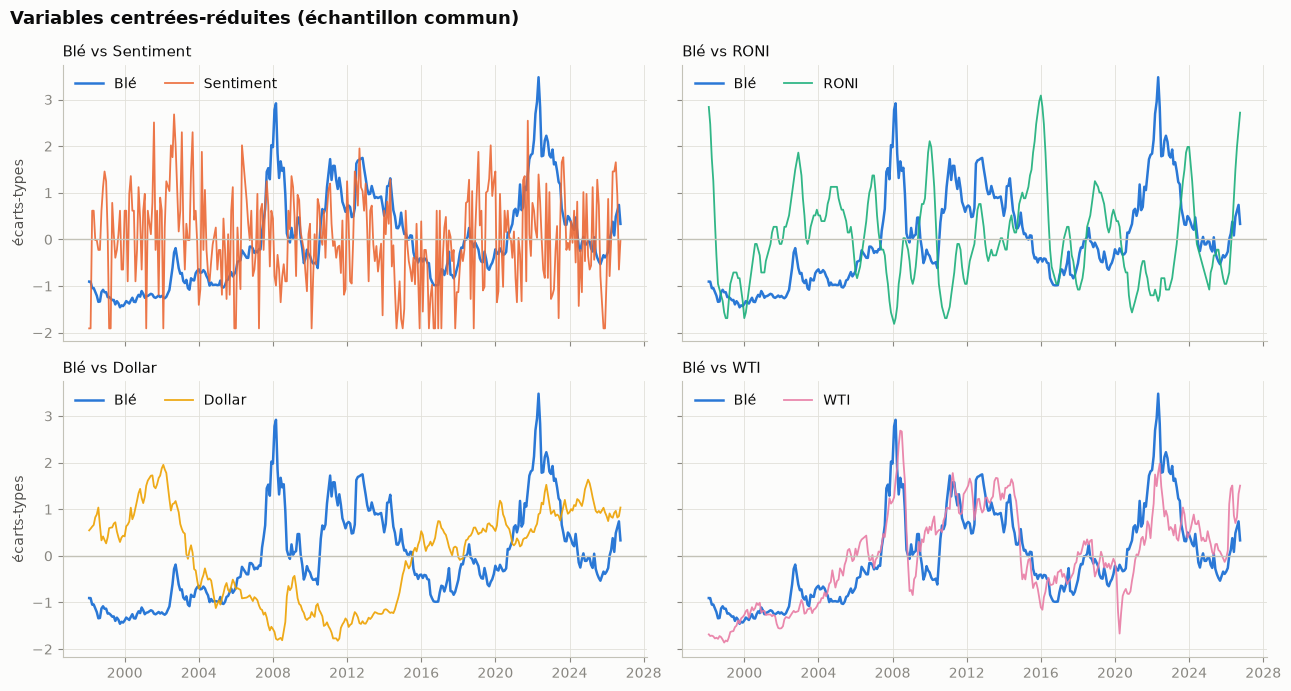

In [9]:
# Variables centrées-réduites : même unité, donc comparables sur un même axe. Blé (bleu) contre chaque variable.
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
for ax, col in zip(axes.ravel(), ["wasde_sentiment", "roni_index", "dxy_index", "wti_price_usd"]):
    ax.plot(panel_z.index, panel_z["wheat_price_usd"], color=COLORS["wheat_price_usd"], label=SHORT["wheat_price_usd"], lw=1.8)
    ax.plot(panel_z.index, panel_z[col], color=COLORS[col], label=SHORT[col], lw=1.3, alpha=0.9)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_title(f"Blé vs {SHORT[col]}")
    ax.legend(loc="upper left", ncol=2)
for ax in axes[1]:
    ax.set_xlabel("")
for ax in axes[:, 0]:
    ax.set_ylabel("écarts-types")
fig.suptitle("Variables centrées-réduites (échantillon commun)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [10]:
# ---- Valeurs extrêmes (sur les variations mensuelles) : réelles ou erreurs ? ----
# Prix en log-différences (variations relatives), RONI et sentiment en différences.
TRANSFORM = {"wheat_price_usd": "dlog", "wti_price_usd": "dlog", "dxy_index": "dlog",
             "wasde_sentiment": "level", "roni_index": "level"}

variation = pd.DataFrame({
    c: (np.log(monthly_all[c]).diff() if TRANSFORM[c] == "dlog" else monthly_all[c].diff())
    for c in monthly_all.columns
})
robust_z = 0.6745 * (variation - variation.median()) / (variation - variation.median()).abs().median()
extremes = (robust_z.stack().rename("z_robuste").to_frame()
            .join(variation.stack().rename("variation")))
extremes = extremes[extremes["z_robuste"].abs() > 4].sort_values("z_robuste", key=abs, ascending=False)
print("Variations mensuelles à plus de 4 écarts absolus médians (z robuste, base MAD) :")
display(extremes.head(15).round(3))
print("\nNombre par variable :", extremes.reset_index()["level_1"].value_counts().to_dict())

Variations mensuelles à plus de 4 écarts absolus médians (z robuste, base MAD) :


,,z_robuste,variation
date,,,
2020-04-01,wti_price_usd,-7.510,-0.568
2020-03-01,wti_price_usd,-7.254,-0.548
2020-05-01,wti_price_usd,6.886,0.546
2008-10-01,dxy_index,5.081,0.072
1998-06-01,roni_index,-4.721,-0.700
2008-12-01,wti_price_usd,-4.457,-0.332
2008-10-01,wheat_price_usd,-4.386,-0.260
2026-03-01,wti_price_usd,4.333,0.348
2012-07-01,wheat_price_usd,4.282,0.250



Nombre par variable : {'roni_index': 7, 'wti_price_usd': 6, 'wheat_price_usd': 2, 'dxy_index': 1}


## 4. Étude des données : corrélations

### 4.1 Corrélations en niveaux
Les corrélations ci-dessous portent sur les niveaux centrés-réduits (la corrélation est invariante au centrage-réduction). **Attention** : deux séries qui dérivent dans le temps sont souvent corrélées sans lien réel (corrélation « fallacieuse »). La section 4.2 vérifie la stationnarité avant d'interpréter.

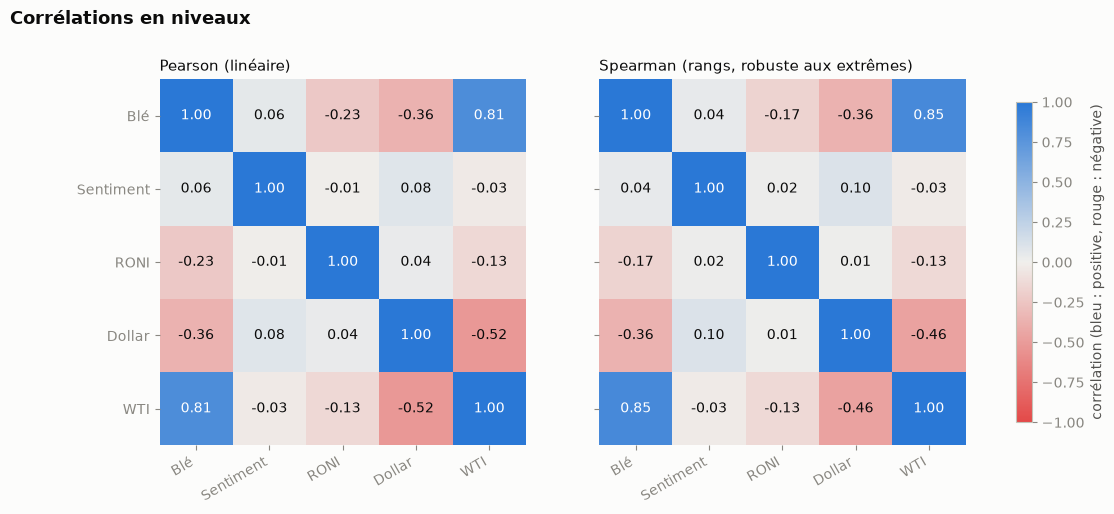

In [11]:
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#e34948", "#f0efec", "#2a78d6"])  # rouge - / gris 0 / bleu +

def heatmap(ax, corr, title, labels, show_y=True):
    names = [labels[c] for c in corr.columns]
    im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=30, ha="right")
    ax.set_yticks(range(len(names)), names if show_y else [])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(len(names)):
        for j in range(len(names)):
            v = corr.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="#ffffff" if abs(v) > 0.6 else INK)
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
heatmap(axes[0], panel_z.corr(), "Pearson (linéaire)", SHORT)
im = heatmap(axes[1], panel_z.corr(method="spearman"), "Spearman (rangs, robuste aux extrêmes)", SHORT, show_y=False)
fig.colorbar(im, ax=axes, shrink=0.8, label="corrélation (bleu : positive, rouge : négative)")
fig.suptitle("Corrélations en niveaux", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.show()

### 4.2 Corrélations des variations mensuelles

Les prix (blé, dollar, WTI) sont passés en variations relatives (Δlog) pour éviter les corrélations fallacieuses entre séries qui dérivent ; le RONI et le sentiment, qui oscillent autour d'une moyenne, restent en niveau.


Échantillon des variations : 335 mois (1998-02 -> 2026-10)


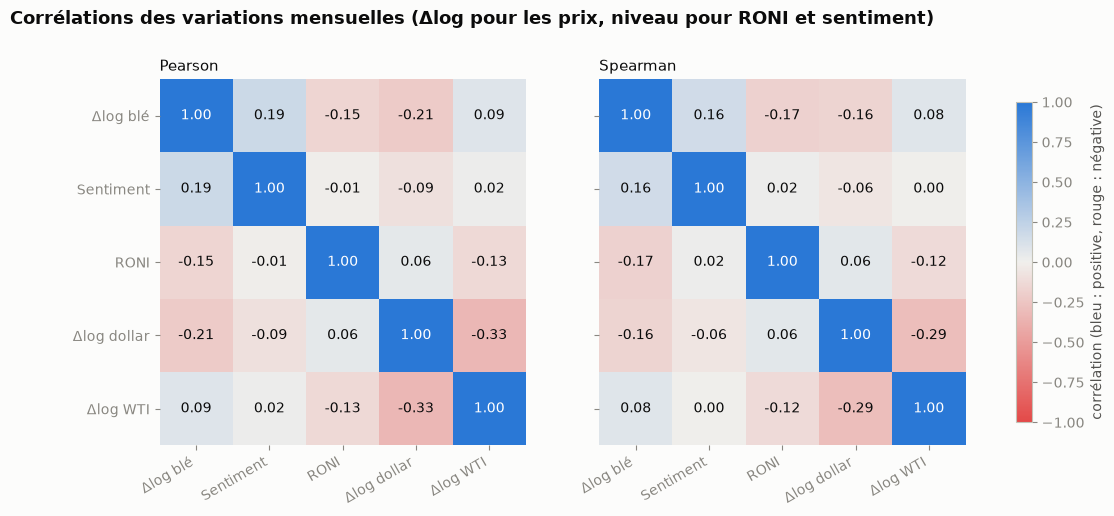

Seuil de significativité approximatif à 5 % : |r| > 0.107 (n = 335)


In [12]:
# Panel de variations : Δlog pour les séries non stationnaires, niveau pour les stationnaires
changes = pd.DataFrame({
    c: (np.log(monthly_all[c]).diff() if TRANSFORM[c] == "dlog" else monthly_all[c])
    for c in monthly_all.columns
})
CHG = {"wheat_price_usd": "Δlog blé", "wti_price_usd": "Δlog WTI", "dxy_index": "Δlog dollar",
       "wasde_sentiment": "Sentiment", "roni_index": "RONI"}
changes_ok = changes.dropna()
print(f"\nÉchantillon des variations : {len(changes_ok)} mois ({changes_ok.index.min():%Y-%m} -> {changes_ok.index.max():%Y-%m})")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
heatmap(axes[0], changes_ok.corr(), "Pearson", CHG)
im = heatmap(axes[1], changes_ok.corr(method="spearman"), "Spearman", CHG, show_y=False)
fig.colorbar(im, ax=axes, shrink=0.8, label="corrélation (bleu : positive, rouge : négative)")
fig.suptitle("Corrélations des variations mensuelles (Δlog pour les prix, niveau pour RONI et sentiment)", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.show()

n = len(changes_ok)
print(f"Seuil de significativité approximatif à 5 % : |r| > {1.96 / np.sqrt(n):.3f} (n = {n})")

### 4.3 Corrélations décalées : qui précède le blé ?

Corrélation entre la variation du blé au mois *t* et chaque variable au mois *t − k*. Pour k > 0, la variable **précède** le blé (utile pour prévoir) ; pour k < 0, c'est le blé qui précède. Les barres colorées dépassent le seuil de significativité à 5 % (bande grisée).

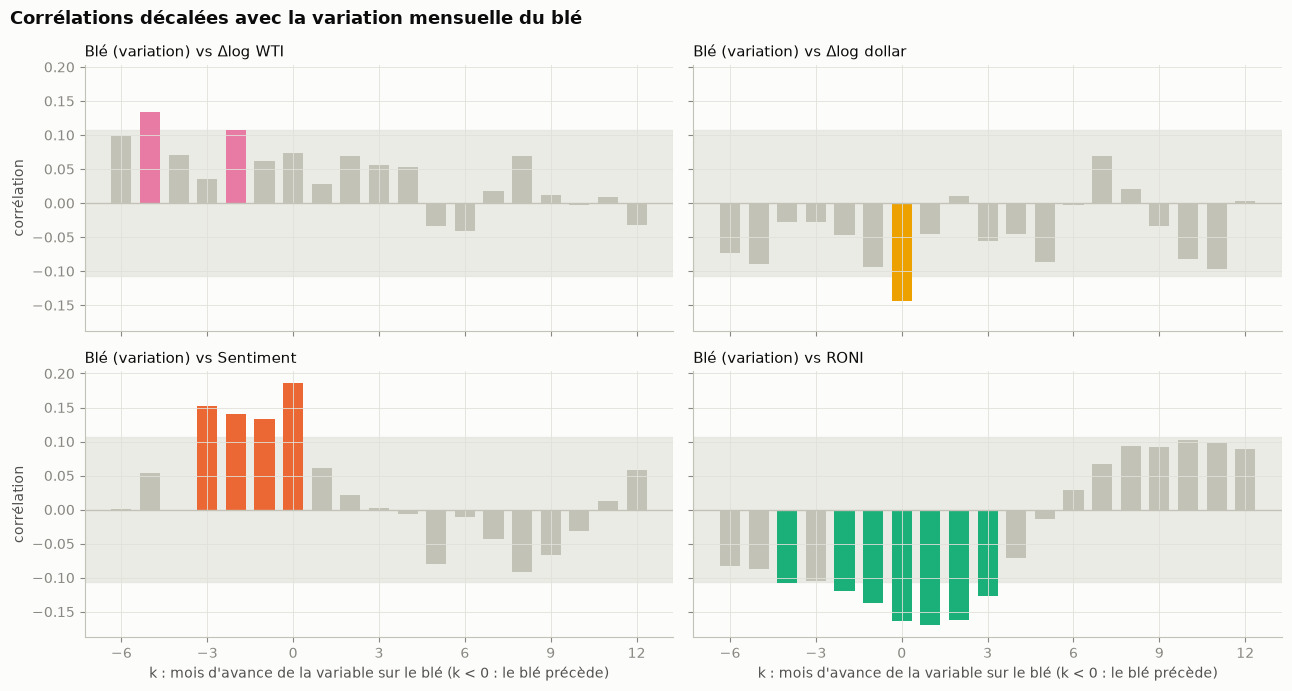

,corr à k=0,meilleur k,corr au meilleur k,seuil 5 %
wti_price_usd,0.073,-5,0.134,0.107
dxy_index,-0.144,0,-0.144,0.107
wasde_sentiment,0.186,0,0.186,0.107
roni_index,-0.164,1,-0.170,0.107


In [13]:
EXPLANATORY = ["wti_price_usd", "dxy_index", "wasde_sentiment", "roni_index"]
LAGS = list(range(-6, 13))
band = 1.96 / np.sqrt(len(changes_ok))

lag_corr = pd.DataFrame({c: [changes["wheat_price_usd"].corr(changes[c].shift(k)) for k in LAGS]
                         for c in EXPLANATORY}, index=pd.Index(LAGS, name="k"))

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True, sharex=True)
for ax, c in zip(axes.ravel(), EXPLANATORY):
    vals = lag_corr[c]
    ax.axhspan(-band, band, color=GRID, alpha=0.6, zorder=0)
    ax.bar(LAGS, vals, width=0.7, color=[COLORS[c] if abs(v) > band else "#c3c2b7" for v in vals])
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_title(f"Blé (variation) vs {CHG[c]}")
    ax.set_xticks(range(-6, 13, 3))
for ax in axes[1]:
    ax.set_xlabel("k : mois d'avance de la variable sur le blé (k < 0 : le blé précède)")
for ax in axes[:, 0]:
    ax.set_ylabel("corrélation")
fig.suptitle("Corrélations décalées avec la variation mensuelle du blé", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

best = pd.DataFrame({
    "corr à k=0": lag_corr.loc[0],
    "meilleur k": lag_corr.abs().idxmax(),
    "corr au meilleur k": [lag_corr.loc[lag_corr[c].abs().idxmax(), c] for c in lag_corr.columns],
}).round(3)
best["seuil 5 %"] = round(band, 3)
display(best)

### 4.4 Stabilité dans le temps : corrélation glissante sur 60 mois

Une corrélation moyenne peut cacher des changements de régime (par exemple la hausse de 2007-2008 ou la crise ukrainienne de 2022).

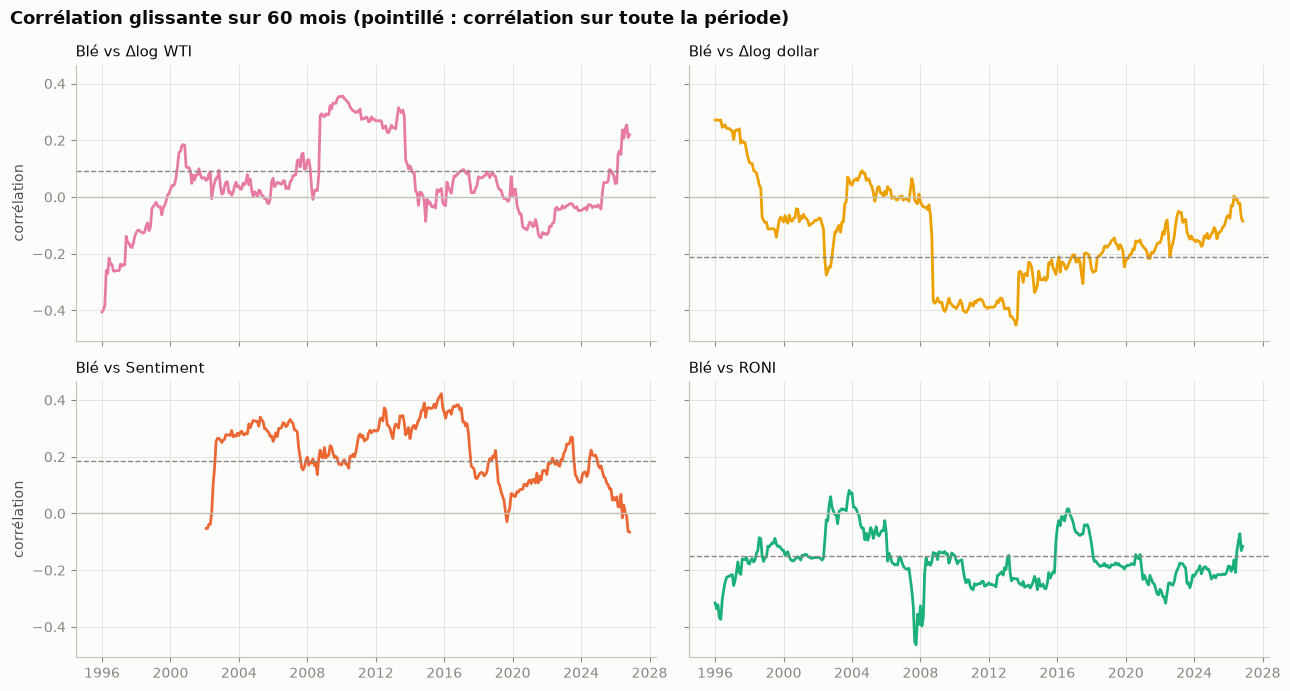

In [14]:
WINDOW = 60
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True, sharex=True)
for ax, c in zip(axes.ravel(), EXPLANATORY):
    rolling = changes["wheat_price_usd"].rolling(WINDOW, min_periods=48).corr(changes[c])
    ax.plot(rolling.index, rolling, color=COLORS[c], lw=2)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.axhline(changes_ok.corr().loc["wheat_price_usd", c], color=MUTED, lw=1, ls="--")
    ax.set_title(f"Blé vs {CHG[c]}")
for ax in axes[:, 0]:
    ax.set_ylabel("corrélation")
fig.suptitle(f"Corrélation glissante sur {WINDOW} mois (pointillé : corrélation sur toute la période)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Modèle

### 5.1 Spécification
On prévoit la **variation du prix du blé du mois suivant** (Δlog), en n'utilisant que des informations disponibles au moment de la décision (voir le calendrier en partie 6).

$$\Delta\log P_{t+1} = a + b_1\,\Delta\log \text{WTI}_{t-1} + b_2\,\Delta\log \text{Dollar}_{t-1} + b_3\,\text{Sentiment}_{t-1} + b_4\,\text{El Niño}_{t-2} + b_5\,\text{La Niña}_{t-2} + b_6\,\Delta\text{RONI}_{t-2} + \varepsilon$$

Les **3 variables climatiques** remplacent le RONI en niveau. Elles reprennent la définition des épisodes ENSO de la NOAA (seuil de ±0,5 °C) :
- **El Niño** = max(RONI − 0,5 ; 0) : intensité d'un épisode chaud ;
- **La Niña** = max(−0,5 − RONI ; 0) : intensité d'un épisode froid ;
- **ΔRONI** = variation mensuelle du RONI : sens d'évolution de l'épisode.

Elles permettent un effet **non linéaire** : un RONI neutre (entre −0,5 et +0,5) n'a pas d'effet, et El Niño et La Niña peuvent agir différemment. L'étude du collègue (`Wheat_Data.ipynb`) a montré que ce codage porte l'essentiel du pouvoir prédictif.

**Décalages** : on prend la dernière valeur connue à la décision. Elle date de *t − 1* pour le WTI, le dollar et le sentiment, et de *t − 2* pour le RONI, publié le mois suivant. Un mois sans rapport WASDE reprend le dernier rapport publié. Les décalages sont fixés a priori, sans recherche sur les données.

### 5.2 Évaluation hors échantillon (70 % / 30 %)
Le modèle est estimé sur les 70 % premiers mois, puis évalué sur les 30 % suivants. Une ligne est retirée entre les deux : la cible du dernier mois d'apprentissage n'est connue qu'après la première décision de test. On compare :
- la **régression linéaire ordinaire** (moindres carrés, MCO), avec les 3 variables climatiques puis avec le RONI en niveau (spécification précédente) ;
- les **régressions pénalisées** avec les 3 variables climatiques. Ce sont les moindres carrés avec une pénalité sur la taille des coefficients, ce qui limite le sur-apprentissage :
  - **Ridge** : pénalité sur le carré des coefficients, qui les rapproche tous de 0 ;
  - **Lasso** : pénalité sur leur valeur absolue, qui peut en annuler certains (sélection automatique de variables).

  Pour les deux, les variables sont centrées-réduites sur l'apprentissage, et l'intensité de la pénalité est choisie par validation croisée chronologique à l'intérieur de l'apprentissage.

In [15]:
import statsmodels.api as sm
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ols_model = lambda: LinearRegression()
ridge_model = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13), cv=TimeSeriesSplit(5)))
lasso_model = lambda: make_pipeline(StandardScaler(), LassoCV(cv=TimeSeriesSplit(5)))

def make_model_data(monthly):
    # Ligne t : cible = rendement log du blé entre t et t+1 ; variables datées t-1 (t-2 pour le climat)
    roni = monthly["roni_index"]
    base = {
        "Δlog WTI": (np.log(monthly["wti_price_usd"]).diff(), 1),
        "Δlog dollar": (np.log(monthly["dxy_index"]).diff(), 1),
        "Sentiment WASDE": (monthly["wasde_sentiment"].ffill(), 1),   # dernier rapport publié
        "RONI": (roni, 2),
        "El Niño": ((roni - 0.5).clip(lower=0), 2),
        "La Niña": ((-0.5 - roni).clip(lower=0), 2),
        "ΔRONI": (roni.diff(), 2),
    }
    log_wheat = np.log(monthly["wheat_price_usd"])
    data = pd.DataFrame({"y": log_wheat.shift(-1) - log_wheat, **{n: s.shift(k) for n, (s, k) in base.items()}})
    data["sigma_hat"] = log_wheat.diff().shift(1).rolling(36).std() * np.sqrt(12)   # volatilité connue en t-1
    data = data.loc[monthly["wasde_sentiment"].first_valid_index():].dropna(subset=["y"])
    assert len(data) == len(pd.date_range(data.index[0], data.index[-1], freq="MS")), "mois manquants"
    return data

SPECS = {
    "3 variables climatiques": ["Δlog WTI", "Δlog dollar", "Sentiment WASDE", "El Niño", "La Niña", "ΔRONI"],
    "RONI en niveau (spécification précédente)": ["Δlog WTI", "Δlog dollar", "Sentiment WASDE", "RONI"],
}
MAIN = "3 variables climatiques"
model_data = make_model_data(monthly_all)

sample = model_data.dropna()
n_train = int(0.7 * len(sample))
train, test = sample.iloc[:n_train - 1], sample.iloc[n_train:]   # une ligne retirée entre apprentissage et test
print(f"Apprentissage : {train.index[0]:%Y-%m} -> {train.index[-1]:%Y-%m} ({len(train)} mois) | "
      f"test : {test.index[0]:%Y-%m} -> {test.index[-1]:%Y-%m} ({len(test)} mois)")

def oos_scores(r2_train, pred):
    return {"R² apprentissage": r2_train,
            "R² test": 1 - ((test["y"] - pred) ** 2).sum() / ((test["y"] - train["y"].mean()) ** 2).sum(),
            "RMSE test modèle": np.sqrt(((test["y"] - pred) ** 2).mean()),
            "RMSE test variation nulle": np.sqrt((test["y"] ** 2).mean()),
            "taux de bon signe (test)": (np.sign(pred) == np.sign(test["y"])).mean()}

scores, tstats = {}, {}
for name, cols in SPECS.items():
    ols = sm.OLS(train["y"], sm.add_constant(train[cols])).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    scores[f"MCO — {name}"] = oos_scores(ols.rsquared, ols.predict(sm.add_constant(test[cols], has_constant="add")))
    tstats[f"MCO — {name}"] = ols.tvalues.drop("const")
penalized = {}
for name, make in {"Ridge": ridge_model, "Lasso": lasso_model}.items():
    fit = make().fit(train[SPECS[MAIN]], train["y"])
    scores[f"{name} — {MAIN}"] = oos_scores(fit.score(train[SPECS[MAIN]], train["y"]), fit.predict(test[SPECS[MAIN]]))
    penalized[f"{name} (pénalité {fit[-1].alpha_:.2g})"] = pd.Series(fit[-1].coef_, index=SPECS[MAIN])
display(pd.DataFrame(scores).T.round(3))
print("t-stats Newey-West (12 retards) des MCO sur l'apprentissage :")
display(pd.DataFrame(tstats).round(2))
print("Coefficients des régressions pénalisées (variables centrées-réduites) :")
display(pd.DataFrame(penalized).round(5))

Apprentissage : 1998-03 -> 2018-01 (239 mois) | test : 2018-03 -> 2026-09 (103 mois)


,R² apprentissage,R² test,RMSE test modèle,RMSE test variation nulle,taux de bon signe (test)
MCO — 3 variables climatiques,0.061,0.032,0.067,0.069,0.612
MCO — RONI en niveau (spécification précédente),0.017,0.037,0.067,0.069,0.592
Ridge — 3 variables climatiques,0.041,0.027,0.068,0.069,0.631
Lasso — 3 variables climatiques,0.044,0.025,0.068,0.069,0.583


t-stats Newey-West (12 retards) des MCO sur l'apprentissage :


,MCO — 3 variables climatiques,MCO — RONI en niveau (spécification précédente)
El Niño,-1.89,NaN
La Niña,-0.58,NaN
RONI,NaN,-1.80
Sentiment WASDE,0.83,0.60
ΔRONI,-2.06,NaN
Δlog WTI,1.01,0.99
Δlog dollar,0.76,0.65


Coefficients des régressions pénalisées (variables centrées-réduites) :


,Ridge (pénalité 3.2e+02),Lasso (pénalité 0.0054)
Δlog WTI,0.00152,0.00000
Δlog dollar,0.00100,0.00000
Sentiment WASDE,0.00127,0.00000
El Niño,-0.00372,-0.00339
La Niña,-0.00032,-0.00000
ΔRONI,-0.00616,-0.00886


## 6. Portefeuille

On parcourt le temps mois par mois. À chaque date *t*, on choisit une position $w_t \in [-1, 1]$ sur le blé (fraction du capital ; négative = vente à découvert). Elle est soumise à une **contrainte de risque** : volatilité annualisée ex ante au plus égale à σ. Quatre niveaux de risque sont testés, σ = 10 %, 15 %, 20 % et 25 %, fixés a priori et non choisis d'après les performances. On compare la valeur de 1 $ investi à :
- **1 $ de blé conservé** depuis la première date (buy & hold) ;
- une **position qui suit une marche aléatoire** (1 000 trajectoires).

Le modèle de la partie 5 (3 variables climatiques) est estimé de trois façons : **régression linéaire ordinaire (MCO)**, **Ridge** et **Lasso**.

### Calendrier des décisions (pas de look-ahead)
| Moment | Ce qui se passe |
|---|---|
| fin du mois *t − 1* | on connaît le blé, le WTI, le dollar et le sentiment jusqu'à *t − 1*, le RONI jusqu'à *t − 2* ; on calcule $w_t$ |
| mois *t* | la position est construite au prix moyen du mois $P_t$ |
| mois *t + 1* | elle est dénouée au prix moyen $P_{t+1}$ : rendement $R_{t+1} = P_{t+1}/P_t - 1$ |

Les prix du FMI sont des moyennes mensuelles : une position décidée fin *t − 1* ne peut pas être exécutée au prix moyen de *t − 1*, déjà écoulé.

### Calcul de la position
1. **Prévision** $\hat y_t$ par le modèle de la partie 5, **ré-estimé chaque mois** (walk-forward) sur les seules lignes dont la cible est déjà connue (*s* ≤ *t − 2*). Pour la Ridge et la Lasso, la normalisation et le choix de la pénalité sont refaits à chaque date sur ces seules lignes.
2. **Conviction** $c_t = \tanh\big((\hat y_t - m_t)/s_t\big)$, où $m_t$ et $s_t$ sont la moyenne et l'écart-type des prévisions du modèle sur son échantillon d'apprentissage. Une prévision nettement au-dessus (au-dessous) de l'habitude donne une conviction proche de +1 (−1).
3. **Ciblage de volatilité** : $w^*_t = \text{clip}(c_t \cdot \sigma / \hat\sigma_t, -1, 1)$, où $\hat\sigma_t$ est la volatilité du blé sur les 36 derniers mois connus.
4. **Lissage** : $w_t = \lambda w_{t-1} + (1 - \lambda) w^*_t$, pour limiter les allers-retours et les coûts.

In [16]:
SIGMAS = [0.10, 0.15, 0.20, 0.25]   # volatilités annualisées cibles, fixées a priori
MIN_TRAIN = 60          # mois d'apprentissage minimum avant la première position
SMOOTH = 0.5            # lambda du lissage
COST = 0.001            # coût par unité de position échangée (10 points de base)
N_PATHS, RW_STEP, SEED = 1000, 0.25, 0   # marche aléatoire : trajectoires, écart-type du pas, graine

MODELS = {f"{name} — {MAIN}": (SPECS[MAIN], make)
          for name, make in {"MCO": ols_model, "Ridge": ridge_model, "Lasso": lasso_model}.items()}
COLORS_MODELS = dict(zip(MODELS, ["#eb6834", "#1baf7a", "#6250d6"]))   # MCO orange, Ridge vert, Lasso violet

def walk_forward(data, cols, make_model):
    out = pd.DataFrame(np.nan, index=data.index, columns=["pred", "center", "scale"])
    for i, t in enumerate(data.index):
        train = data.iloc[:max(i - 1, 0)].dropna(subset=cols + ["y"])   # lignes s <= t-2
        if len(train) < MIN_TRAIN or data.loc[t, cols].isna().any():
            continue
        model = make_model().fit(train[cols], train["y"])
        fitted = model.predict(train[cols])
        out.loc[t] = model.predict(data.loc[[t], cols])[0], fitted.mean(), fitted.std()
    return out

# Prévisions walk-forward : elles ne dépendent pas de σ, on les calcule une seule fois
WF = {name: walk_forward(model_data, cols, make) for name, (cols, make) in MODELS.items()}
first = max(wf["pred"].first_valid_index() for wf in WF.values())
trading = pd.Series(model_data.index >= first, index=model_data.index)
R = np.expm1(model_data["y"])   # rendement simple réalisé par la position décidée en t

# Marche aléatoire : exposition u_t = clip(u_{t-1} + ε_t, -1, 1), tirée une fois pour toutes les volatilités
rng = np.random.default_rng(SEED)
steps = rng.normal(0, RW_STEP, (len(model_data), N_PATHS))
U = np.zeros_like(steps)
for i in range(1, len(U)):
    U[i] = np.clip(U[i - 1] + steps[i], -1, 1)
U = pd.DataFrame(U, index=model_data.index)
print(f"Décisions : {model_data.index[0]:%Y-%m} -> {model_data.index[-1]:%Y-%m} ; positions à partir de {first:%Y-%m}")

Décisions : 1998-02 -> 2026-09 ; positions à partir de 2003-04



=== Volatilité cible σ = 10% ===


,rendement annualisé,volatilité annualisée,ratio de Sharpe,perte maximale,part des marches aléatoires au Sharpe supérieur,|position| moyenne,rotation mensuelle
Buy & hold (1 $ de blé),0.023,0.254,0.217,-0.697,0.191,NaN,NaN
MCO — 3 variables climatiques,0.036,0.050,0.728,-0.089,0.001,0.176,0.083
Ridge — 3 variables climatiques,0.035,0.049,0.725,-0.087,0.001,0.171,0.082
Lasso — 3 variables climatiques,0.027,0.045,0.602,-0.130,0.004,0.172,0.066
Marche aléatoire (médiane),-0.004,0.070,-0.019,-0.384,NaN,NaN,NaN


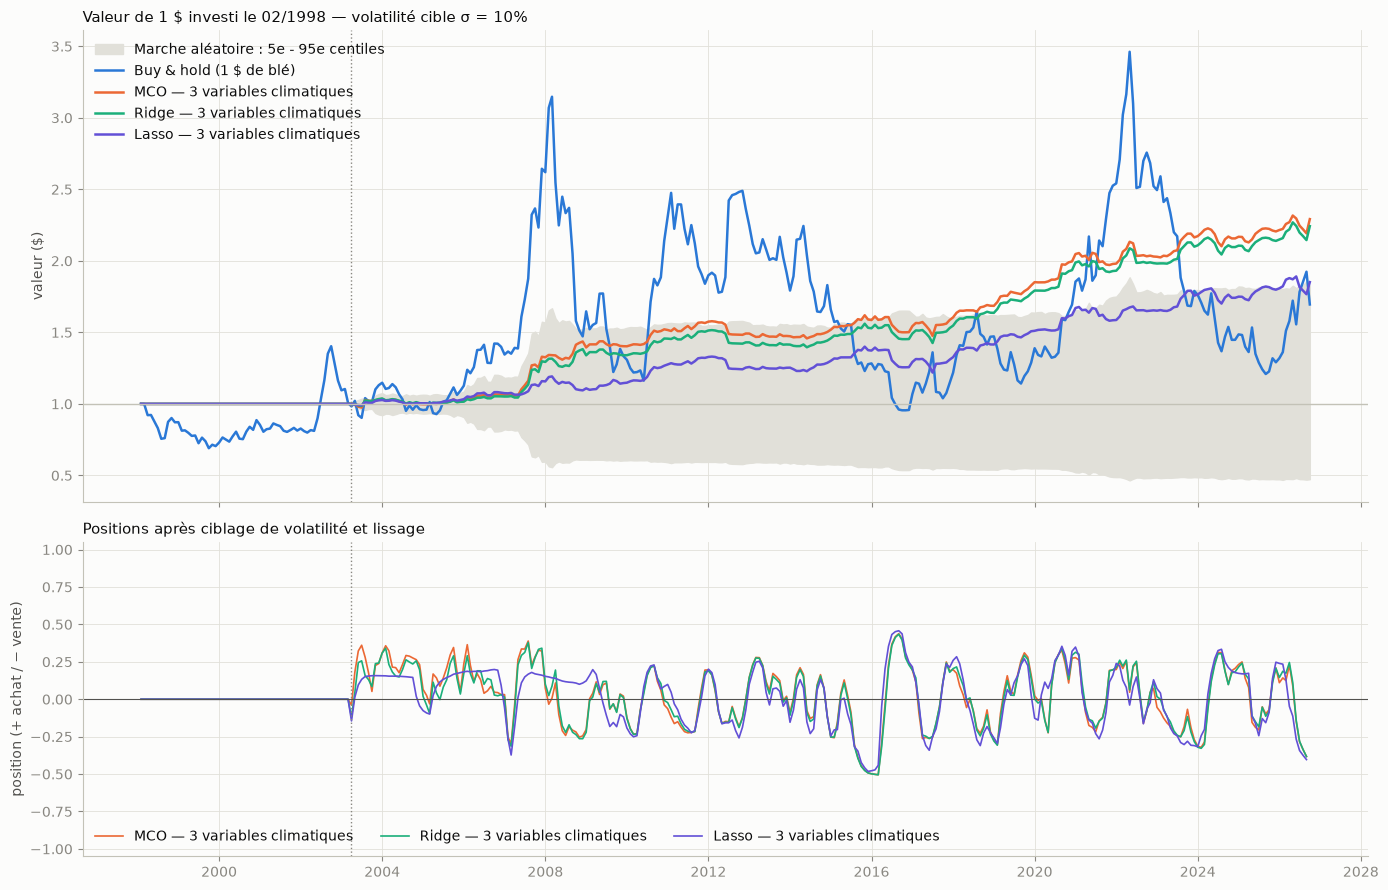


=== Volatilité cible σ = 15% ===


,rendement annualisé,volatilité annualisée,ratio de Sharpe,perte maximale,part des marches aléatoires au Sharpe supérieur,|position| moyenne,rotation mensuelle
Buy & hold (1 $ de blé),0.023,0.254,0.217,-0.697,0.191,NaN,NaN
MCO — 3 variables climatiques,0.053,0.075,0.728,-0.132,0.001,0.264,0.125
Ridge — 3 variables climatiques,0.052,0.074,0.725,-0.129,0.001,0.257,0.123
Lasso — 3 variables climatiques,0.039,0.068,0.602,-0.190,0.004,0.258,0.099
Marche aléatoire (médiane),-0.007,0.106,-0.019,-0.525,NaN,NaN,NaN


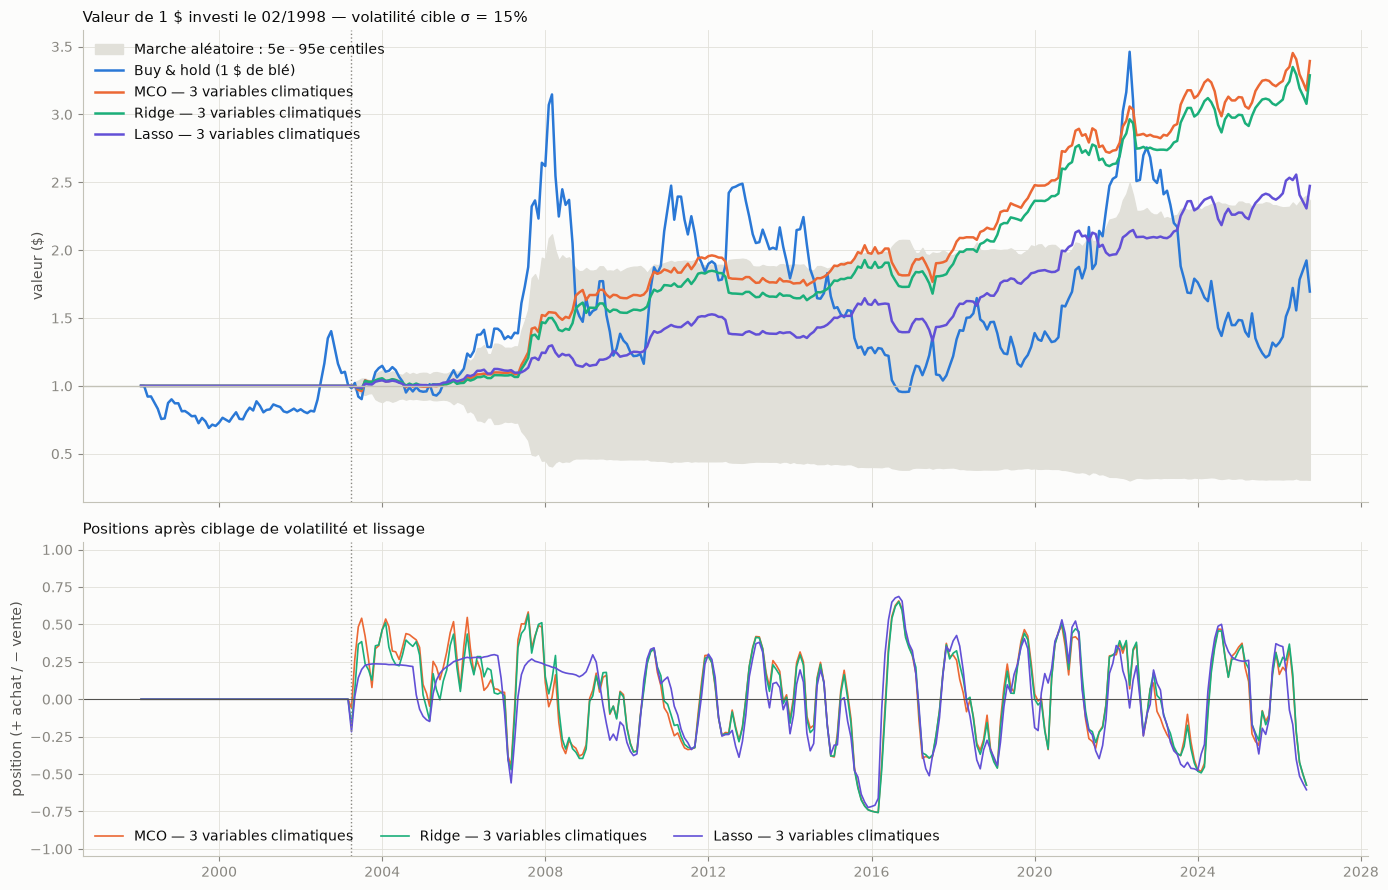


=== Volatilité cible σ = 20% ===


,rendement annualisé,volatilité annualisée,ratio de Sharpe,perte maximale,part des marches aléatoires au Sharpe supérieur,|position| moyenne,rotation mensuelle
Buy & hold (1 $ de blé),0.023,0.254,0.217,-0.697,0.181,NaN,NaN
MCO — 3 variables climatiques,0.070,0.100,0.725,-0.174,0.001,0.351,0.166
Ridge — 3 variables climatiques,0.068,0.098,0.724,-0.169,0.001,0.342,0.163
Lasso — 3 variables climatiques,0.052,0.091,0.603,-0.247,0.003,0.344,0.131
Marche aléatoire (médiane),-0.011,0.138,-0.012,-0.628,NaN,NaN,NaN


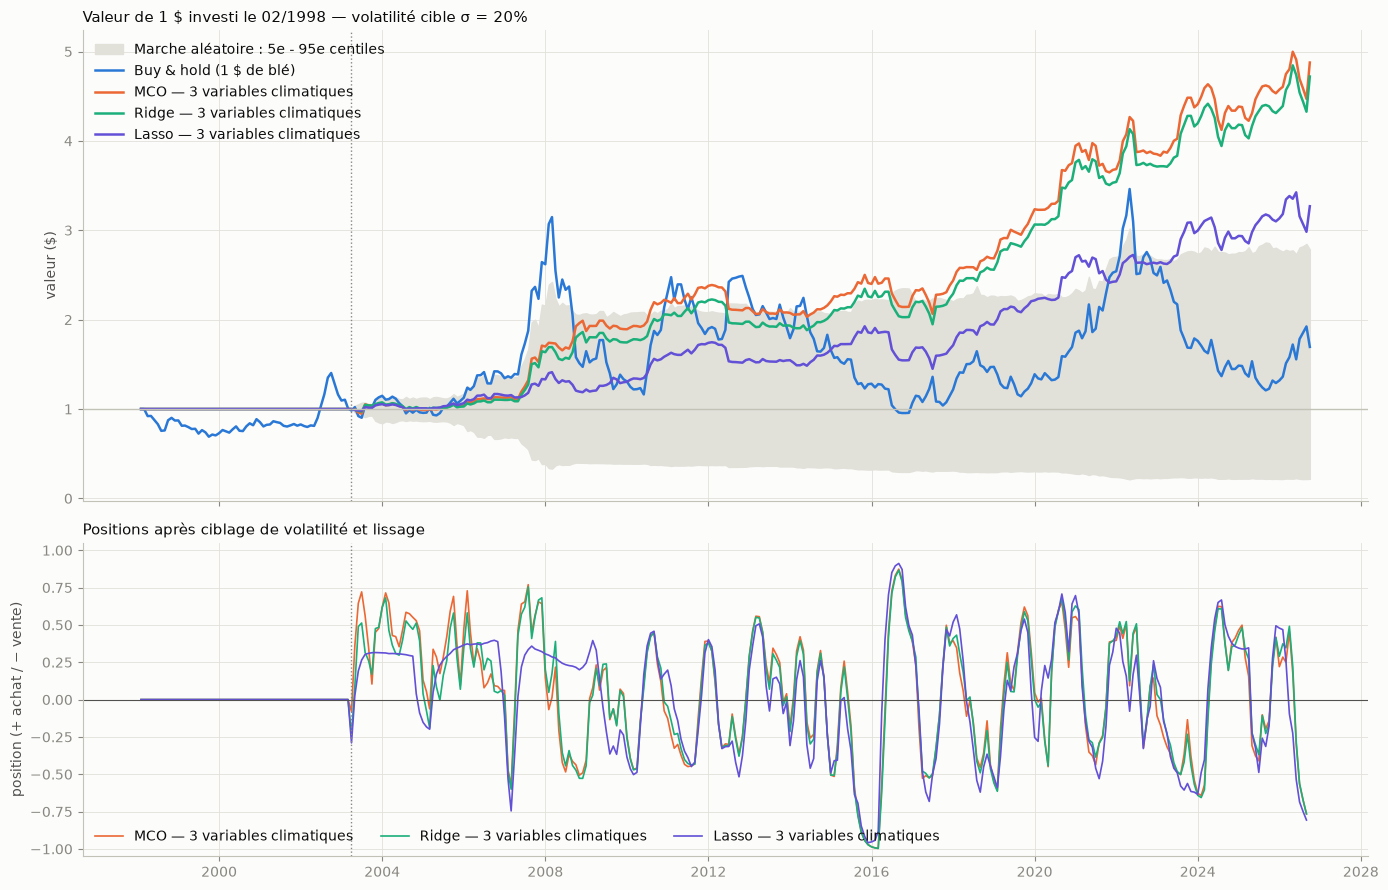


=== Volatilité cible σ = 25% ===


,rendement annualisé,volatilité annualisée,ratio de Sharpe,perte maximale,part des marches aléatoires au Sharpe supérieur,|position| moyenne,rotation mensuelle
Buy & hold (1 $ de blé),0.023,0.254,0.217,-0.697,0.172,NaN,NaN
MCO — 3 variables climatiques,0.085,0.121,0.733,-0.187,0.001,0.425,0.203
Ridge — 3 variables climatiques,0.083,0.119,0.731,-0.191,0.001,0.414,0.200
Lasso — 3 variables climatiques,0.066,0.110,0.632,-0.265,0.001,0.420,0.160
Marche aléatoire (médiane),-0.014,0.155,-0.012,-0.671,NaN,NaN,NaN


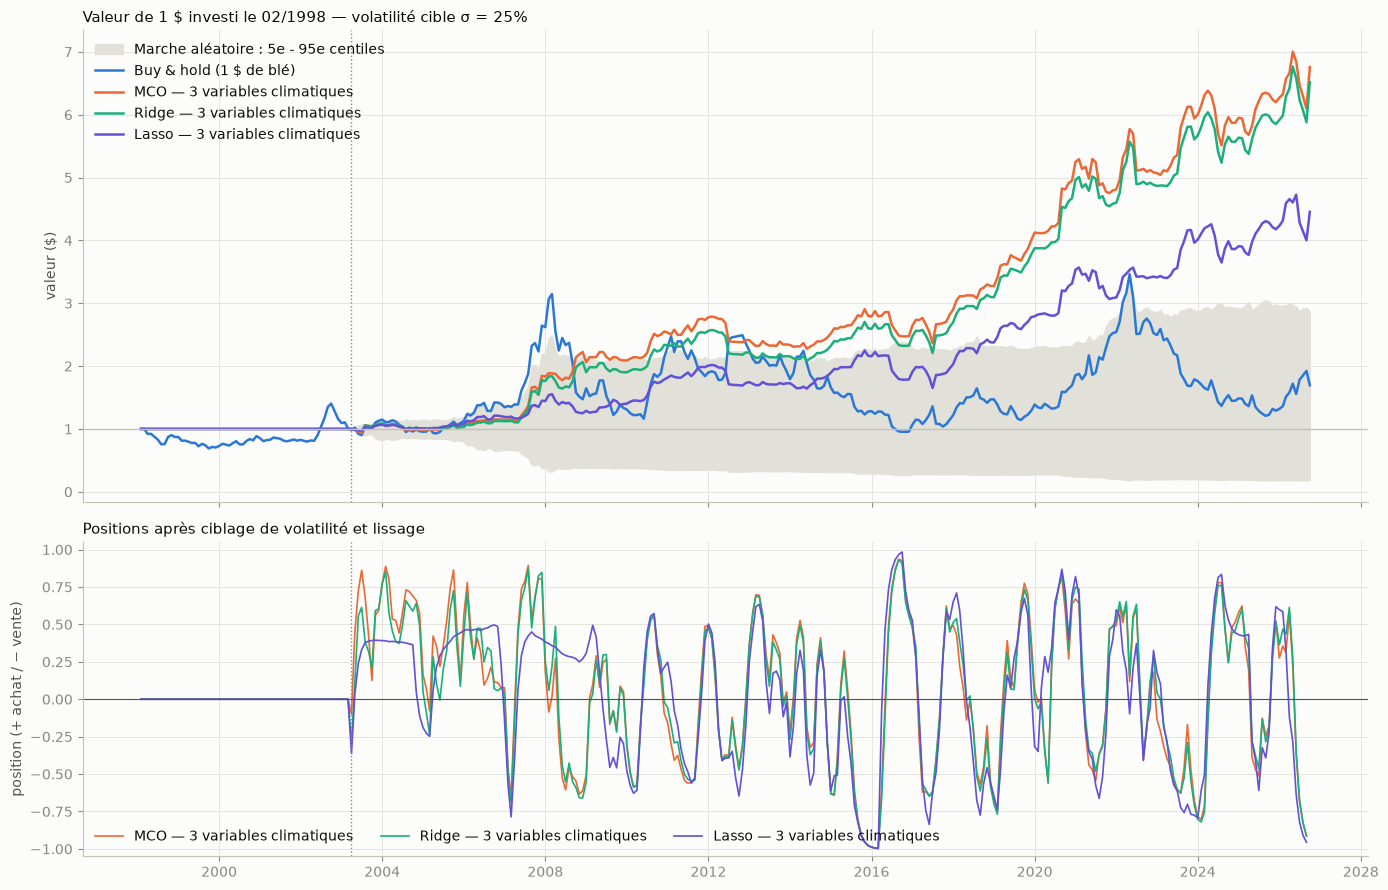

,vol réelle MCO,vol réelle Ridge,vol réelle Lasso,Sharpe MCO,Sharpe Ridge,Sharpe Lasso
σ cible,,,,,,
10%,0.050,0.049,0.045,0.728,0.725,0.602
15%,0.075,0.074,0.068,0.728,0.725,0.602
20%,0.100,0.098,0.091,0.725,0.724,0.603
25%,0.121,0.119,0.110,0.733,0.731,0.632


In [17]:
def position(wf, sigma):
    conviction = np.tanh((wf["pred"] - wf["center"]) / wf["scale"].replace(0, np.nan))
    target = (conviction * sigma / model_data["sigma_hat"]).clip(-1, 1).fillna(0)
    return target.ewm(alpha=1 - SMOOTH, adjust=False).mean()   # w_t = λ w_{t-1} + (1-λ) w*_t

def pnl(w):
    return w.mul(R, axis=0) - COST * w.diff().abs().fillna(w.abs())

def wealth(p):   # valeur de 1 $ ; le résultat de la ligne t est réalisé en t+1
    v = (1 + p).cumprod()
    v.index = v.index + pd.offsets.MonthBegin(1)
    return pd.concat([p.iloc[:1] * 0 + 1, v])

def metrics(p):
    p = p.loc[first:]
    v = (1 + p).cumprod()
    return pd.Series({"rendement annualisé": v.iloc[-1] ** (12 / len(p)) - 1,
                      "volatilité annualisée": p.std() * np.sqrt(12),
                      "ratio de Sharpe": p.mean() / p.std() * np.sqrt(12),
                      "perte maximale": (v / v.cummax() - 1).min()})

def scenario(sigma):
    positions = pd.DataFrame({m: position(WF[m], sigma) for m in MODELS})
    risk_scale = (sigma / model_data["sigma_hat"]).clip(upper=1)
    rw_positions = U.mul(risk_scale * trading, axis=0).fillna(0)
    pnls = {"Buy & hold (1 $ de blé)": R, **{m: pnl(positions[m]) for m in MODELS}}
    rw_metrics = pnl(rw_positions).apply(metrics)
    perf = pd.DataFrame({k: metrics(v) for k, v in pnls.items()}).T
    perf["part des marches aléatoires au Sharpe supérieur"] = [
        (rw_metrics.loc["ratio de Sharpe"] >= s).mean() for s in perf["ratio de Sharpe"]]
    perf.loc["Marche aléatoire (médiane)"] = rw_metrics.median(axis=1)
    w = positions.loc[first:]
    perf["|position| moyenne"] = w.abs().mean()
    perf["rotation mensuelle"] = w.diff().abs().mean()
    return {"positions": positions, "perf": perf,
            "values": pd.DataFrame({k: wealth(v) for k, v in pnls.items()}),
            "rw": wealth(pnl(rw_positions))}

def plot_scenario(sigma, s):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
    ax1.fill_between(s["rw"].index, s["rw"].quantile(0.05, axis=1), s["rw"].quantile(0.95, axis=1),
                     color=GRID, label="Marche aléatoire : 5e - 95e centiles")
    for name, color in {"Buy & hold (1 $ de blé)": "#2a78d6", **COLORS_MODELS}.items():
        ax1.plot(s["values"].index, s["values"][name], color=color, lw=1.8, label=name)
    ax1.axhline(1, color="#c3c2b7", lw=1)
    ax1.set_title(f"Valeur de 1 $ investi le {model_data.index[0]:%m/%Y} — volatilité cible σ = {sigma:.0%}")
    ax1.set_ylabel("valeur ($)")
    ax1.legend(loc="upper left")
    for m, color in COLORS_MODELS.items():
        ax2.plot(s["positions"].index, s["positions"][m], color=color, lw=1.2, label=m)
    ax2.axhline(0, color=INK2, lw=0.8)
    ax2.set_ylim(-1.05, 1.05)
    ax2.set_title("Positions après ciblage de volatilité et lissage")
    ax2.set_ylabel("position (+ achat / − vente)")
    ax2.legend(loc="lower left", ncol=3)
    for ax in (ax1, ax2):
        ax.axvline(first, color=MUTED, ls=":", lw=1)
    fig.tight_layout()
    plt.show()

SCEN = {sigma: scenario(sigma) for sigma in SIGMAS}
for sigma in SIGMAS:
    print(f"\n=== Volatilité cible σ = {sigma:.0%} ===")
    display(SCEN[sigma]["perf"].round(3))
    plot_scenario(sigma, SCEN[sigma])

# Volatilité réelle et Sharpe par niveau de σ
rows = []
for sigma in SIGMAS:
    perf = SCEN[sigma]["perf"]
    row = {"σ cible": f"{sigma:.0%}"}
    row.update({f"vol réelle {m.split(' ')[0]}": perf.loc[m, "volatilité annualisée"] for m in MODELS})
    row.update({f"Sharpe {m.split(' ')[0]}": perf.loc[m, "ratio de Sharpe"] for m in MODELS})
    rows.append(row)
display(pd.DataFrame(rows).set_index("σ cible").round(3))

### Commentaire : volatilité cible, volatilité réelle et Sharpe

Sur la période de trading (2003-04 → 2026-10) :

| σ cible | Vol réelle MCO | Vol réelle Ridge | Vol réelle Lasso | Sharpe MCO | Sharpe Ridge | Sharpe Lasso |
|---|---|---|---|---|---|---|
| 10 % | 5,0 % | 4,9 % | 4,5 % | 0,73 | 0,73 | 0,60 |
| 15 % | 7,5 % | 7,4 % | 6,8 % | 0,73 | 0,73 | 0,60 |
| 20 % | 10,0 % | 9,8 % | 9,1 % | 0,73 | 0,72 | 0,60 |
| 25 % | 12,1 % | 11,9 % | 11,0 % | 0,73 | 0,73 | 0,63 |

- **Vol réelle < σ cible à tous les niveaux** : la moitié environ du budget de risque est utilisée, car la conviction dépasse rarement ±1 et le lissage réduit encore les positions. Le ratio vol réelle / σ cible est d'environ 0,5 (MCO) et 0,44 (Lasso). La contrainte est donc respectée *ex ante*, sans être saturée.
- **Sharpe quasi constant** : le Sharpe ne dépend pas du niveau de σ, puisque tout le portefeuille est proportionnel à σ. Seules les pertes et les gains absolus changent. Le Sharpe de la Lasso reste plus bas (0,60) à tous les niveaux.
- **Le choix de σ ne crée donc pas de performance** : il règle seulement le niveau de risque accepté. À σ = 25 %, la perte maximale dépasse 20 % pour la MCO, contre −70 % pour le buy & hold ; la comparaison doit donc se faire à risque égal, non à σ identique.

### Contrôle anti look-ahead
Test placebo : on remplace toutes les données à partir de `T0` par du bruit, puis on relance les trois modèles à σ = 10 %. Si aucune information future n'est utilisée, les positions décidées jusqu'à `T0` inclus doivent rester identiques.

In [18]:
T0 = pd.Timestamp("2015-01-01")
noisy = monthly_all.copy()
after = noisy.index >= T0
noisy.loc[after] = noisy.loc[after].mask(noisy.loc[after].notna(),
                                         np.abs(np.random.default_rng(1).normal(50, 20, noisy.loc[after].shape)))
noisy_data = make_model_data(noisy)
for m, (cols, make) in MODELS.items():
    check = position(walk_forward(noisy_data, cols, make), SIGMAS[0])
    ref = SCEN[SIGMAS[0]]["positions"][m]
    print(f"{m} : positions jusqu'à {T0:%Y-%m} identiques : {np.allclose(check.loc[:T0], ref.loc[:T0])} ; "
          f"positions après modifiées : {not np.allclose(check.loc[T0:].iloc[1:], ref.loc[T0:].iloc[1:])}")

MCO — 3 variables climatiques : positions jusqu'à 2015-01 identiques : True ; positions après modifiées : True


Ridge — 3 variables climatiques : positions jusqu'à 2015-01 identiques : True ; positions après modifiées : True


Lasso — 3 variables climatiques : positions jusqu'à 2015-01 identiques : True ; positions après modifiées : True


### Hypothèses et limites
- **Exécution** : au prix moyen du mois (achats et ventes étalés), sans contrat à terme ni coût de portage ; cash à 0 % ; vente à découvert sans coût ; coûts de 10 points de base par unité échangée.
- **Risque** : la contrainte est respectée *ex ante* ($|w_t|\,\hat\sigma_t \le \sigma$) ; la volatilité réalisée peut s'en écarter.
- **Paramètres fixés a priori** (σ = 10 % à 25 %, λ, fenêtres, décalages) : les quatre niveaux de σ sont présentés côte à côte, sans en retenir un d'après sa performance.
- **Choix du codage climatique** : il s'inspire d'un résultat obtenu sur ces mêmes données (étude du collègue). Le risque de sur-apprentissage n'est donc pas nul, et la stabilité par sous-période doit être vérifiée.
- **Données** : séries actuelles et non telles que publiées à l'époque (révisions éventuelles du FMI et du RONI).